# PlantSeg Stage 1 — Session 1: Train Models 1–4

Trains the first 4 models and saves their `result_*.pkl` files:
1. **MobileNetV3Large**
2. **EfficientNetB0**
3. **ResNet50**
4. **EfficientNetV2S**

**Output:** `result_MobileNetV3Large.pkl`, `result_EfficientNetB0.pkl`, `result_ResNet50.pkl`, `result_EfficientNetV2S.pkl`  
saved to `/kaggle/working/s1_results/`

> After this session ends, **download all `.pkl` and `.pt` files** from the output.  
> Then run **Session 2** to train models 5–8.

> **Kaggle note:** Internet **ON** required for `timm` pretrained weights.  
> Lower `IMG_SIZE_CNN` to `320` or `256` if you hit GPU OOM.

## Section 1 — Install Dependencies & Imports

Installs `timm`, `imagehash`, `statsmodels`, and `grad-cam`, then imports all required libraries and sets a global random seed for reproducibility.

In [1]:
!pip install -q timm imagehash statsmodels grad-cam
import os, json, math, time, random, warnings, pickle
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision; from torchvision import transforms
import timm
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, precision_score,
                             recall_score, matthews_corrcoef, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, auc)
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid", context="talk")
SEED=42; random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu"); print("Device:", device)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 95.0 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 77.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
distributed-ucxx-cu12 0.48.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is incompatible.
cuml-cu12 26.2.0 requires numba<0.62.0,>=0.60.0, but you have numba 0.65.1 which is incompatible.
cuml-cu12 26.2.0 requires numba-cuda[cu12]<0.23.0,>=0.22.1, but you have numba-cuda 0.30.2 which is inco

## Section 2 — Global Configuration

Set `DATA_ROOT` to the PlantSeg dataset mount and `OUTDIR` to the output directory.
All 8 models share the same hyperparameters defined here. Change `MODELS_TO_TRAIN`
to run a subset, or set `QUICK_SMOKE = True` for a fast sanity-check (1 epoch,
8 images per class).


In [2]:
# ============ CONFIG ============
# Edit DATA_ROOT to point at your PlantSeg dataset mount
DATA_ROOT = Path("/kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg")
if not (DATA_ROOT/"Metadata.csv").exists():
    for cand in [Path("/kaggle/input/plantseg"), Path("plantseg"), Path(".")]:
        if (cand/"Metadata.csv").exists(): DATA_ROOT=cand; break
assert (DATA_ROOT/"Metadata.csv").exists(), f"Metadata.csv not found under {DATA_ROOT} — edit DATA_ROOT."

OUTDIR = Path("/kaggle/working/s1_results"); FIG = OUTDIR/"figures"
OUTDIR.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)

# List of all 8 models to train sequentially.
# Remove any name from this list to skip it.
MODELS_TO_TRAIN = [
    "MobileNetV3Large",  # Trainer 1/8
    "EfficientNetB0",    # Trainer 2/8
    "ResNet50",          # Trainer 3/8
    "EfficientNetV2S",   # Trainer 4/8
    "ConvNeXtV2Tiny",    # Trainer 5/8
    "ViTBase16",         # Trainer 6/8 — transformer
    "SwinTiny",          # Trainer 7/8 — transformer
    "GatedFusionLight",  # Trainer 8/8 — dual-branch fusion
]

SCOPE = "full"   # "full" = all plants | "fruit" = fruit hosts only
FRUIT_HOSTS = {"Apple","Citrus","Grape","Banana","Peach","Blueberry",
               "Plum","Cherry","Raspberry","Strawberry"}

NUM_EPOCHS      = 40
PATIENCE        = 8
LR              = 3e-4
WEIGHT_DECAY    = 1e-4
USE_PRETRAINED  = True
USE_CLASS_WEIGHTS = True
LABEL_SMOOTHING = 0.05
IMG_SIZE_CNN    = 384   # lower to 320 or 256 if OOM
USE_RANDAUG     = True
USE_TTA         = True
QUICK_SMOKE     = False  # True → 1 epoch, 8 imgs/class (fast sanity check)

print("DATA_ROOT:", DATA_ROOT)
print("Models to train:", MODELS_TO_TRAIN)


DATA_ROOT: /kaggle/input/datasets/mdmarufbangabashi/plantseg/plantseg
Models to train: ['MobileNetV3Large', 'EfficientNetB0', 'ResNet50', 'EfficientNetV2S', 'ConvNeXtV2Tiny', 'ViTBase16', 'SwinTiny', 'GatedFusionLight']


## Section 3 — Dataset Index & Class Weights

Reads `Metadata.csv`, resolves image paths, filters to `SCOPE`, and computes
inverse-frequency class weights used in the cross-entropy loss.
Prints split sizes and number of disease classes.


In [3]:
# ============ DATA INDEX ============
meta = pd.read_csv(DATA_ROOT/"Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training":"train","Validation":"val","Test":"test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT/"images"/r["split"]/r["Name"], axis=1)
meta["label"] = meta["Disease"]; meta["plant"] = meta["Plant"]
if SCOPE == "fruit":
    meta = meta[meta["plant"].isin(FRUIT_HOSTS)].reset_index(drop=True)
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)

CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label2idx = {c: i for i, c in enumerate(CLASS_NAMES)}

train_df = meta[meta.split=="train"].reset_index(drop=True)
val_df   = meta[meta.split=="val"].reset_index(drop=True)
test_df  = meta[meta.split=="test"].reset_index(drop=True)

if QUICK_SMOKE:
    train_df = train_df.groupby("label",group_keys=False).head(8).reset_index(drop=True)
    val_df   = val_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    test_df  = test_df.groupby("label",group_keys=False).head(4).reset_index(drop=True)
    NUM_EPOCHS = 1

counts = train_df["label"].map(label2idx).value_counts().reindex(range(NUM_CLASSES)).fillna(0)
inv = np.where(counts.values > 0, 1.0/counts.values, 0.0)
cw  = inv / inv[inv>0].mean()
class_weights = torch.tensor(cw, dtype=torch.float32, device=device)

print(f"classes={NUM_CLASSES}  train={len(train_df)}  val={len(val_df)}  test={len(test_df)}")


classes=115  train=5367  val=846  test=1561


## Section 4 — Transforms & Dataset Class

`make_transforms(sz)` returns a pair of `(train_transform, eval_transform)`.
Training uses `RandAugment` + `RandomErasing` when `USE_RANDAUG=True`, otherwise
falls back to rotation and colour-jitter.  
`DS` is a lightweight `torch.utils.data.Dataset` wrapper over the metadata DataFrame.


In [4]:
# ============ TRANSFORMS / DATASET ============
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]

def make_transforms(sz):
    ops = [transforms.RandomResizedCrop(sz, scale=(0.7,1.0)),
           transforms.RandomHorizontalFlip(),
           transforms.RandomVerticalFlip(p=0.2)]
    if USE_RANDAUG:
        ops += [transforms.RandAugment(num_ops=2, magnitude=9)]
    else:
        ops += [transforms.RandomRotation(15),
                transforms.ColorJitter(0.2, 0.2, 0.2, 0.05)]
    ops += [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if USE_RANDAUG:
        ops += [transforms.RandomErasing(p=0.25)]
    ev = transforms.Compose([transforms.Resize((sz,sz)),
                             transforms.ToTensor(),
                             transforms.Normalize(MEAN, STD)])
    return transforms.Compose(ops), ev

class DS(Dataset):
    def __init__(self, d, t):
        self.df = d.reset_index(drop=True); self.t = t
    def __len__(self):
        return len(self.df)
    def __getitem__(self, i):
        r = self.df.iloc[i]
        return self.t(Image.open(r.filepath).convert("RGB")), label2idx[r.label]


## Section 5 — Model Zoo

`build_backbone(name, num_classes)` returns a `(model, img_size, batch_size)` tuple
for the 7 single-backbone architectures.  
`GatedFusionLightModel` is the custom dual-branch fusion model: it fuses
**MobileNetV3Large** and **EfficientNetB0** features through a learned soft-gate
before the final classifier.


In [5]:
# ============ MODEL ZOO ============
def build_backbone(name, num_classes, pretrained=USE_PRETRAINED):
    if name == "MobileNetV3Large":
        m = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, num_classes)
        return m, IMG_SIZE_CNN, 24
    if name == "EfficientNetB0":
        return timm.create_model("efficientnet_b0", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 24
    if name == "ResNet50":
        m = torchvision.models.resnet50(weights="IMAGENET1K_V2" if pretrained else None)
        m.fc = nn.Linear(m.fc.in_features, num_classes)
        return m, IMG_SIZE_CNN, 16
    if name == "EfficientNetV2S":
        return timm.create_model("tf_efficientnetv2_s", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 12
    if name == "ConvNeXtV2Tiny":
        return timm.create_model("convnextv2_tiny", pretrained=pretrained, num_classes=num_classes), IMG_SIZE_CNN, 16
    if name == "ViTBase16":
        return timm.create_model("vit_base_patch16_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    if name == "SwinTiny":
        return timm.create_model("swin_tiny_patch4_window7_224", pretrained=pretrained, num_classes=num_classes), 224, 16
    raise ValueError(name)

class _Gated(nn.Module):
    def __init__(self, ba, da, bb, db, nc, gh, hh, dr):
        super().__init__(); self.branch_a=ba; self.branch_b=bb; fused=da+db
        self.gate = nn.Sequential(nn.Linear(fused,gh), nn.ReLU(), nn.Linear(gh,2), nn.Softmax(dim=1))
        self.classifier = nn.Sequential(nn.Linear(fused,hh), nn.ReLU(), nn.Dropout(dr), nn.Linear(hh,nc))
    def forward(self, x):
        fa, fb = self.branch_a(x), self.branch_b(x)
        g = self.gate(torch.cat([fa,fb], 1))
        return self.classifier(torch.cat([fa*g[:,0:1], fb*g[:,1:2]], 1))

def GatedFusionLightModel(nc, pretrained=USE_PRETRAINED):
    mb = torchvision.models.mobilenet_v3_large(weights="IMAGENET1K_V2" if pretrained else None)
    da = mb.classifier[0].in_features; mb.classifier = nn.Identity()
    b  = timm.create_model("efficientnet_b0", pretrained=pretrained, num_classes=0, global_pool="avg")
    return _Gated(mb, da, b, b.num_features, nc, 128, 256, 0.3)

FUSION_MODELS = {"GatedFusionLight": GatedFusionLightModel}


## Section 6 — Training & Metric Helper Functions

- `train_one(model_name)` — full training loop with AdamW, linear warm-up +
  cosine annealing LR schedule, AMP mixed precision, early stopping, and TTA
  (horizontal-flip) at inference.  
- `compute_metrics(y, yp, ypb, n)` — computes accuracy, balanced accuracy,
  macro/weighted F1, precision, recall, MCC, ROC-AUC, and macro specificity.  
- `deployment(model, img_size)` — counts parameters, measures checkpoint size,
  and benchmarks CPU/GPU latency.


In [6]:
# ============ TRAIN / METRICS HELPERS ============
def train_one(model_name, num_epochs=NUM_EPOCHS, patience=PATIENCE):
    if model_name in FUSION_MODELS:
        model = FUSION_MODELS[model_name](NUM_CLASSES).to(device); img_size, bs = 224, 16
    else:
        model, img_size, bs = build_backbone(model_name, NUM_CLASSES); model = model.to(device)
    ttf, etf = make_transforms(img_size)
    tl = DataLoader(DS(train_df, ttf), batch_size=bs, shuffle=True,  num_workers=2, pin_memory=True, drop_last=True)
    vl = DataLoader(DS(val_df,   etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    te = DataLoader(DS(test_df,  etf), batch_size=bs, shuffle=False, num_workers=2, pin_memory=True)
    is_tf = model_name in ("ViTBase16","SwinTiny")
    lr = 5e-5 if is_tf else LR; warm_ep = 3 if is_tf else 2; pat = 10 if is_tf else patience
    opt  = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    warm = torch.optim.lr_scheduler.LinearLR(opt, start_factor=0.1, total_iters=warm_ep)
    cos  = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(1, num_epochs-warm_ep))
    sch  = torch.optim.lr_scheduler.SequentialLR(opt, [warm, cos], milestones=[warm_ep])
    crit = nn.CrossEntropyLoss(weight=class_weights if USE_CLASS_WEIGHTS else None, label_smoothing=LABEL_SMOOTHING)
    scaler = torch.cuda.amp.GradScaler(enabled=device.type=="cuda")
    hist = {"train_loss":[], "val_loss":[], "train_acc":[], "val_acc":[]}; best=-1; best_state=None; bad=0
    for ep in range(num_epochs):
        model.train(); run=cor=tot=0
        for x,y in tl:
            x,y = x.to(device),y.to(device); opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=device.type=="cuda"):
                out = model(x); loss = crit(out, y)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            run += loss.item()*x.size(0); cor += (out.argmax(1)==y).sum().item(); tot += y.size(0)
        trl, tra = run/tot, cor/tot
        model.eval(); vr=vc=vt=0
        with torch.no_grad():
            for x,y in vl:
                x,y = x.to(device),y.to(device); out = model(x); loss = crit(out,y)
                vr += loss.item()*x.size(0); vc += (out.argmax(1)==y).sum().item(); vt += y.size(0)
        vlo, vac = vr/vt, vc/vt; sch.step()
        for k,v in zip(hist, [trl,vlo,tra,vac]): hist[k].append(v)
        print(f"[{model_name}] ep{ep+1}/{num_epochs} lr={opt.param_groups[0]['lr']:.1e} "
              f"trL={trl:.3f} vL={vlo:.3f} trA={tra:.3f} vA={vac:.3f}")
        if vac > best+1e-4:
            best=vac; best_state={k:v.cpu().clone() for k,v in model.state_dict().items()}; bad=0
        else:
            bad += 1
            if ep >= warm_ep and bad >= pat:
                print(f"  early stop @ ep{ep+1}"); break
    model.load_state_dict(best_state); torch.save(best_state, OUTDIR/f"{model_name}_best.pt")
    model.eval(); P=[]; Y=[]; PR=[]
    with torch.no_grad():
        for x,y in te:
            x = x.to(device); lg = model(x)
            if USE_TTA: lg = lg + model(torch.flip(x, dims=[3]))
            p = F.softmax(lg, 1).cpu().numpy(); P.extend(p.argmax(1)); Y.extend(y.numpy()); PR.extend(p)
    return model, img_size, hist, np.array(Y), np.array(P), np.array(PR)

def deployment(model, img_size, nw=5, ni=30):
    n = sum(p.numel() for p in model.parameters())
    tmp = OUTDIR/"_t.pt"; torch.save(model.state_dict(), tmp)
    sz = os.path.getsize(tmp)/1e6; os.remove(tmp)
    d  = torch.randn(1, 3, img_size, img_size)
    def t(dev):
        m = model.to(dev).eval(); dd = d.to(dev)
        with torch.no_grad():
            for _ in range(nw): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            t0 = time.time()
            for _ in range(ni): m(dd)
            if dev.type=="cuda": torch.cuda.synchronize()
            return (time.time()-t0)/ni*1000
    lg = t(device) if device.type=="cuda" else float("nan")
    lc = t(torch.device("cpu")); model.to(device)
    return {"params_M": n/1e6, "checkpoint_size_MB": sz, "latency_cpu_ms": lc, "latency_gpu_ms": lg}

def compute_metrics(y, yp, ypb, n):
    cm = confusion_matrix(y, yp, labels=range(n)); specs=[]
    for i in range(n):
        tn = cm.sum()-cm[i,:].sum()-cm[:,i].sum()+cm[i,i]; fp = cm[:,i].sum()-cm[i,i]
        specs.append(tn/(tn+fp) if (tn+fp)>0 else float("nan"))
    present = [c for c in range(n) if (y==c).sum()>0]; aucs=[]
    for c in present:
        try: aucs.append(roc_auc_score((y==c).astype(int), ypb[:,c]))
        except Exception: pass
    return {"accuracy": accuracy_score(y,yp),
            "balanced_accuracy": balanced_accuracy_score(y,yp),
            "f1_macro": f1_score(y,yp,average="macro"),
            "f1_weighted": f1_score(y,yp,average="weighted"),
            "precision_macro": precision_score(y,yp,average="macro",zero_division=0),
            "recall_macro": recall_score(y,yp,average="macro",zero_division=0),
            "mcc": matthews_corrcoef(y,yp),
            "roc_auc_macro": float(np.mean(aucs)) if aucs else float("nan"),
            "macro_specificity": float(np.nanmean(specs))}, cm


## Section 7 — Per-Model Figure Helper

`plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size)` draws and saves three
inline plots for each trained model:
1. **Loss & accuracy curves** across epochs  
2. **Row-normalised confusion matrix** heat-map  
3. **Micro + macro ROC curve**


In [7]:
# ============ PER-MODEL FIGURE HELPER ============
def plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size):
    ep = range(1, len(hist["train_loss"])+1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="val")
    ax[0].set_title(f"{MODEL_NAME} — loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(ep, hist["train_acc"],  label="train"); ax[1].plot(ep, hist["val_acc"],  label="val")
    ax[1].set_title(f"{MODEL_NAME} — accuracy"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_loss_acc.png", dpi=200, bbox_inches="tight"); plt.show()

    cm = confusion_matrix(Y, P, labels=range(NUM_CLASSES))
    cmn = cm.astype(float)/cm.astype(float).sum(1, keepdims=True).clip(min=1)
    s = max(7, NUM_CLASSES*0.16)
    plt.figure(figsize=(s,s))
    sns.heatmap(cmn, cmap="viridis", square=True, cbar_kws={"shrink":0.5},
                xticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False,
                yticklabels=CLASS_NAMES if NUM_CLASSES<=45 else False)
    plt.title(f"{MODEL_NAME} — confusion (row-norm)"); plt.xlabel("predicted"); plt.ylabel("true")
    plt.tight_layout(); plt.savefig(FIG/f"{MODEL_NAME}_confusion.png", dpi=150, bbox_inches="tight"); plt.show()

    y_oh = np.eye(NUM_CLASSES)[Y]; fpr,tpr,_ = roc_curve(y_oh.ravel(), PR.ravel()); micro = auc(fpr,tpr)
    present = [c for c in range(NUM_CLASSES) if (Y==c).sum()>0]
    macro_auc = np.mean([auc(*roc_curve((Y==c).astype(int), PR[:,c])[:2]) for c in present])
    plt.figure(figsize=(6.5,6))
    plt.plot(fpr, tpr, lw=2, label=f"micro (AUC={micro:.3f})")
    plt.plot([0,1],[0,1],"k--",lw=1)
    plt.title(f"{MODEL_NAME} — ROC (macro-AUC={macro_auc:.3f})"); plt.xlabel("FPR"); plt.ylabel("TPR")
    plt.legend(loc="lower right"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_roc.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 8 — Grad-CAM Visualisation Helper

`plot_gradcam(MODEL_NAME, model, img_size)` applies Grad-CAM to the last
convolutional layer of CNN-based models and overlays the saliency heat-map on
sample test images from fruit host classes.  
Transformer architectures (ViTBase16, SwinTiny) are skipped here — use attention
rollout in Stage 4 for those.


In [8]:
# ============ GRAD-CAM HELPER ============
def plot_gradcam(MODEL_NAME, model, img_size):
    from pytorch_grad_cam import GradCAM
    from pytorch_grad_cam.utils.image import show_cam_on_image
    def _target_layers(m, name):
        if name == "ResNet50":          return [m.layer4[-1]]
        if name == "MobileNetV3Large":  return [m.features[-1]]
        if name == "ConvNeXtV2Tiny":    return [m.stages[-1]]
        if name in ("EfficientNetB0","EfficientNetV2S"): return [m.conv_head]
        if name == "GatedFusionLight":  return [m.branch_a.features[-1]]
        return None
    _, etf = make_transforms(img_size)
    tl_ = _target_layers(model, MODEL_NAME)
    if tl_ is None:
        print(f"{MODEL_NAME} is a transformer — Grad-CAM skipped (use attention rollout in Stage 4).")
        return
    cam = GradCAM(model=model, target_layers=tl_)
    rows = test_df[test_df.plant.isin(FRUIT_HOSTS)].groupby("label").first().reset_index().head(6)
    fig, axes = plt.subplots(2, len(rows), figsize=(3.2*len(rows), 7))
    for col, (_, r) in zip(axes.T, rows.iterrows()):
        im = Image.open(r.filepath).convert("RGB").resize((img_size, img_size))
        g  = cam(input_tensor=etf(im).unsqueeze(0).to(device))[0]
        col[0].imshow(im); col[0].set_title(r.label, fontsize=8); col[0].axis("off")
        col[1].imshow(show_cam_on_image(np.float32(im)/255.0, g, use_rgb=True)); col[1].axis("off")
    plt.suptitle(f"Grad-CAM — {MODEL_NAME}"); plt.tight_layout()
    plt.savefig(FIG/f"{MODEL_NAME}_gradcam.png", dpi=200, bbox_inches="tight"); plt.show()


## Section 9 — Training Loop: Models 1–4

Trains **MobileNetV3Large**, **EfficientNetB0**, **ResNet50**, **EfficientNetV2S**.  
Each model saves its `result_*.pkl` and `*_best.pt` to `OUTDIR` automatically.

> Download outputs before your session expires!


  Training: MobileNetV3Large

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 193MB/s]


[MobileNetV3Large] ep1/40 lr=1.6e-04 trL=4.927 vL=4.856 trA=0.044 vA=0.158
[MobileNetV3Large] ep2/40 lr=3.0e-04 trL=3.535 vL=2.859 trA=0.314 vA=0.472
[MobileNetV3Large] ep3/40 lr=3.0e-04 trL=2.504 vL=2.963 trA=0.500 vA=0.469
[MobileNetV3Large] ep4/40 lr=3.0e-04 trL=2.003 vL=2.493 trA=0.623 vA=0.586
[MobileNetV3Large] ep5/40 lr=3.0e-04 trL=1.720 vL=2.344 trA=0.707 vA=0.616
[MobileNetV3Large] ep6/40 lr=2.9e-04 trL=1.543 vL=2.345 trA=0.756 vA=0.619
[MobileNetV3Large] ep7/40 lr=2.9e-04 trL=1.442 vL=2.316 trA=0.789 vA=0.635
[MobileNetV3Large] ep8/40 lr=2.8e-04 trL=1.352 vL=2.273 trA=0.819 vA=0.645
[MobileNetV3Large] ep9/40 lr=2.8e-04 trL=1.303 vL=2.250 trA=0.837 vA=0.670
[MobileNetV3Large] ep10/40 lr=2.7e-04 trL=1.255 vL=2.228 trA=0.858 vA=0.673
[MobileNetV3Large] ep11/40 lr=2.6e-04 trL=1.234 vL=2.251 trA=0.864 vA=0.674
[MobileNetV3Large] ep12/40 lr=2.5e-04 trL=1.181 vL=2.216 trA=0.884 vA=0.675
[MobileNetV3Large] ep13/40 lr=2.4e-04 trL=1.146 vL=2.265 trA=0.899 vA=0.700
[MobileNetV3Large] ep

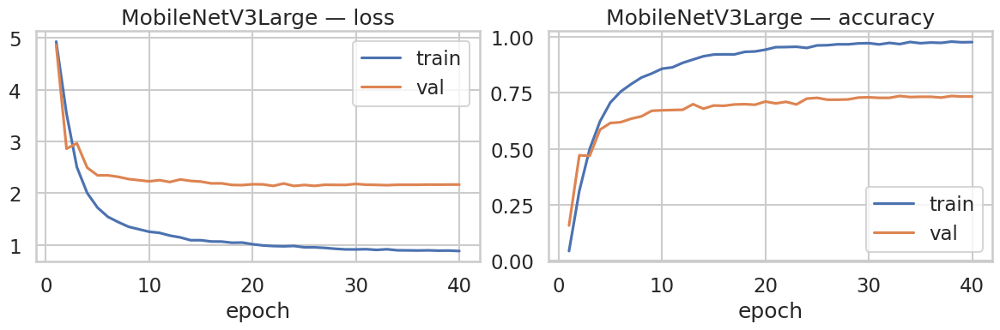

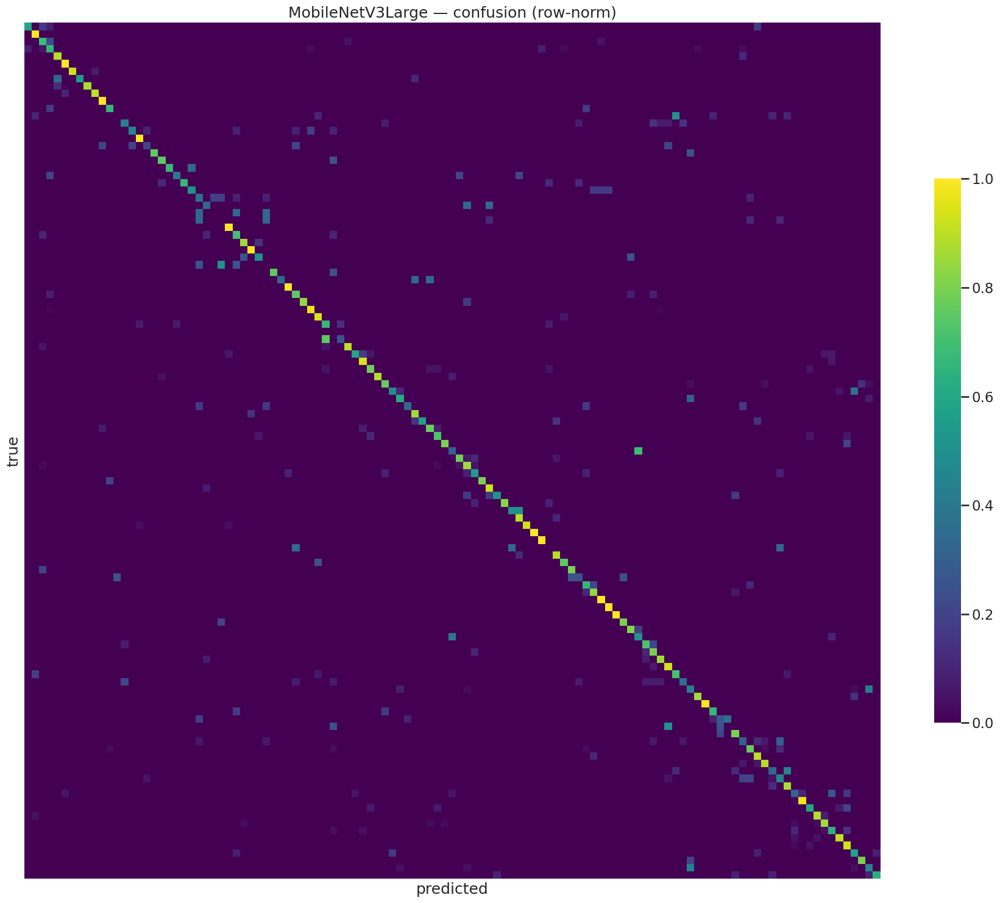

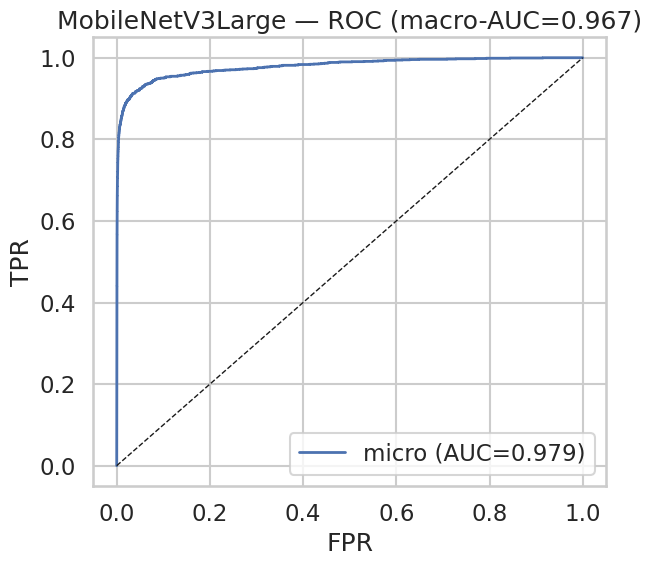

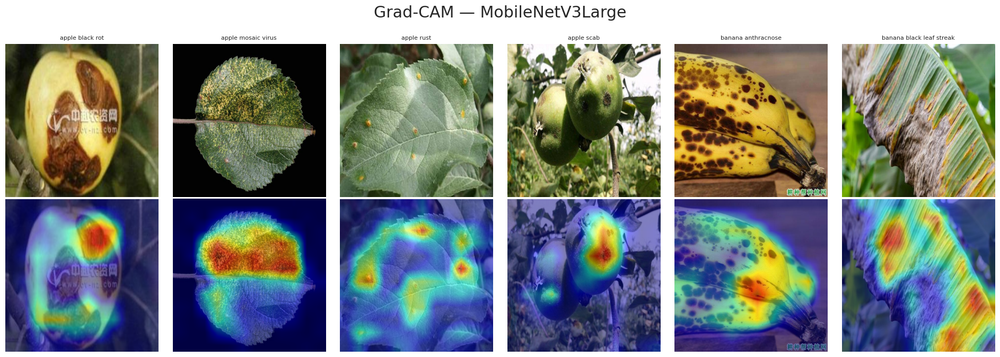


  Training: EfficientNetB0



model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

[EfficientNetB0] ep1/40 lr=1.6e-04 trL=4.992 vL=4.850 trA=0.025 vA=0.061
[EfficientNetB0] ep2/40 lr=3.0e-04 trL=3.635 vL=2.864 trA=0.298 vA=0.485
[EfficientNetB0] ep3/40 lr=3.0e-04 trL=2.382 vL=2.531 trA=0.531 vA=0.557
[EfficientNetB0] ep4/40 lr=3.0e-04 trL=1.833 vL=2.355 trA=0.675 vA=0.618
[EfficientNetB0] ep5/40 lr=3.0e-04 trL=1.607 vL=2.326 trA=0.737 vA=0.641
[EfficientNetB0] ep6/40 lr=2.9e-04 trL=1.441 vL=2.226 trA=0.794 vA=0.667
[EfficientNetB0] ep7/40 lr=2.9e-04 trL=1.302 vL=2.199 trA=0.844 vA=0.678
[EfficientNetB0] ep8/40 lr=2.8e-04 trL=1.234 vL=2.185 trA=0.871 vA=0.668
[EfficientNetB0] ep9/40 lr=2.8e-04 trL=1.199 vL=2.236 trA=0.890 vA=0.680
[EfficientNetB0] ep10/40 lr=2.7e-04 trL=1.195 vL=2.287 trA=0.886 vA=0.658
[EfficientNetB0] ep11/40 lr=2.6e-04 trL=1.143 vL=2.227 trA=0.907 vA=0.687
[EfficientNetB0] ep12/40 lr=2.5e-04 trL=1.103 vL=2.185 trA=0.923 vA=0.691
[EfficientNetB0] ep13/40 lr=2.4e-04 trL=1.066 vL=2.235 trA=0.932 vA=0.674
[EfficientNetB0] ep14/40 lr=2.3e-04 trL=1.058 v

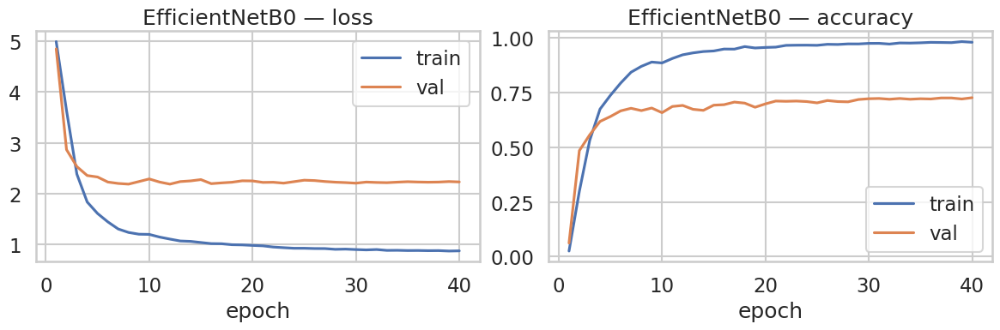

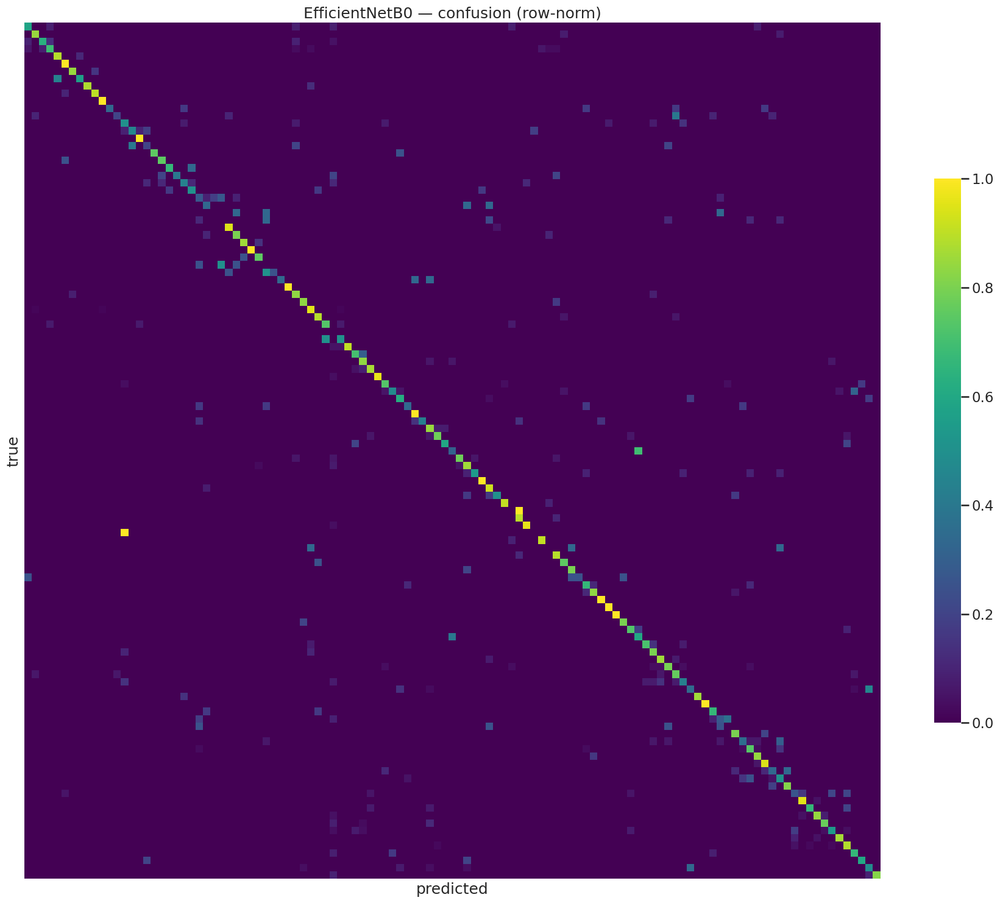

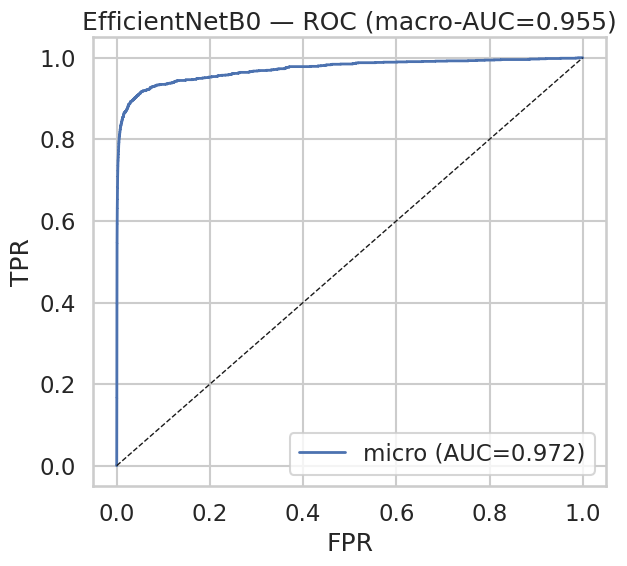

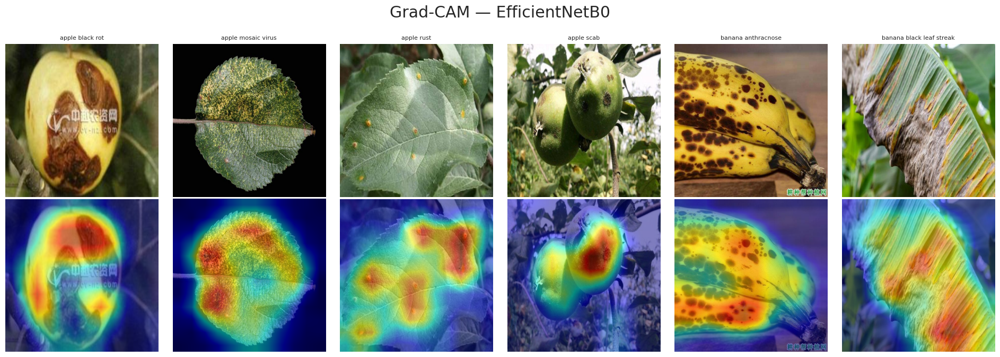


  Training: ResNet50

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 176MB/s]


[ResNet50] ep1/40 lr=1.6e-04 trL=4.903 vL=4.559 trA=0.078 vA=0.225
[ResNet50] ep2/40 lr=3.0e-04 trL=3.468 vL=3.060 trA=0.323 vA=0.450
[ResNet50] ep3/40 lr=3.0e-04 trL=2.784 vL=2.823 trA=0.446 vA=0.505
[ResNet50] ep4/40 lr=3.0e-04 trL=2.319 vL=2.622 trA=0.554 vA=0.589
[ResNet50] ep5/40 lr=3.0e-04 trL=2.041 vL=2.455 trA=0.635 vA=0.611
[ResNet50] ep6/40 lr=2.9e-04 trL=1.893 vL=2.430 trA=0.678 vA=0.634
[ResNet50] ep7/40 lr=2.9e-04 trL=1.735 vL=2.481 trA=0.718 vA=0.619
[ResNet50] ep8/40 lr=2.8e-04 trL=1.601 vL=2.394 trA=0.762 vA=0.661
[ResNet50] ep9/40 lr=2.8e-04 trL=1.507 vL=2.382 trA=0.793 vA=0.636
[ResNet50] ep10/40 lr=2.7e-04 trL=1.433 vL=2.302 trA=0.806 vA=0.669
[ResNet50] ep11/40 lr=2.6e-04 trL=1.394 vL=2.264 trA=0.819 vA=0.669
[ResNet50] ep12/40 lr=2.5e-04 trL=1.306 vL=2.725 trA=0.857 vA=0.623
[ResNet50] ep13/40 lr=2.4e-04 trL=1.293 vL=2.338 trA=0.860 vA=0.676
[ResNet50] ep14/40 lr=2.3e-04 trL=1.233 vL=2.285 trA=0.880 vA=0.682
[ResNet50] ep15/40 lr=2.2e-04 trL=1.236 vL=2.252 trA=0.88

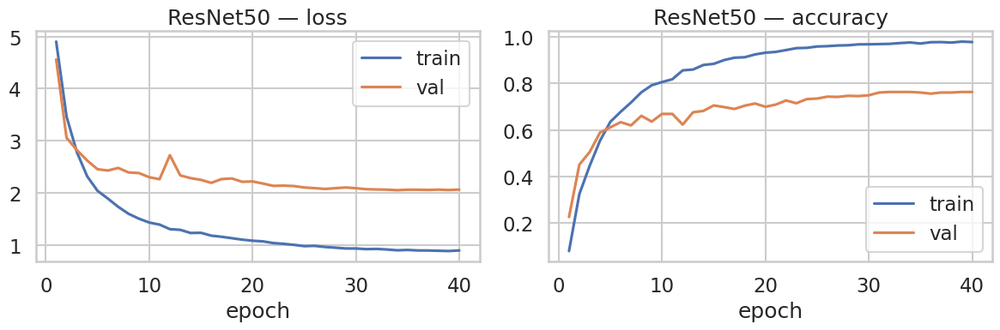

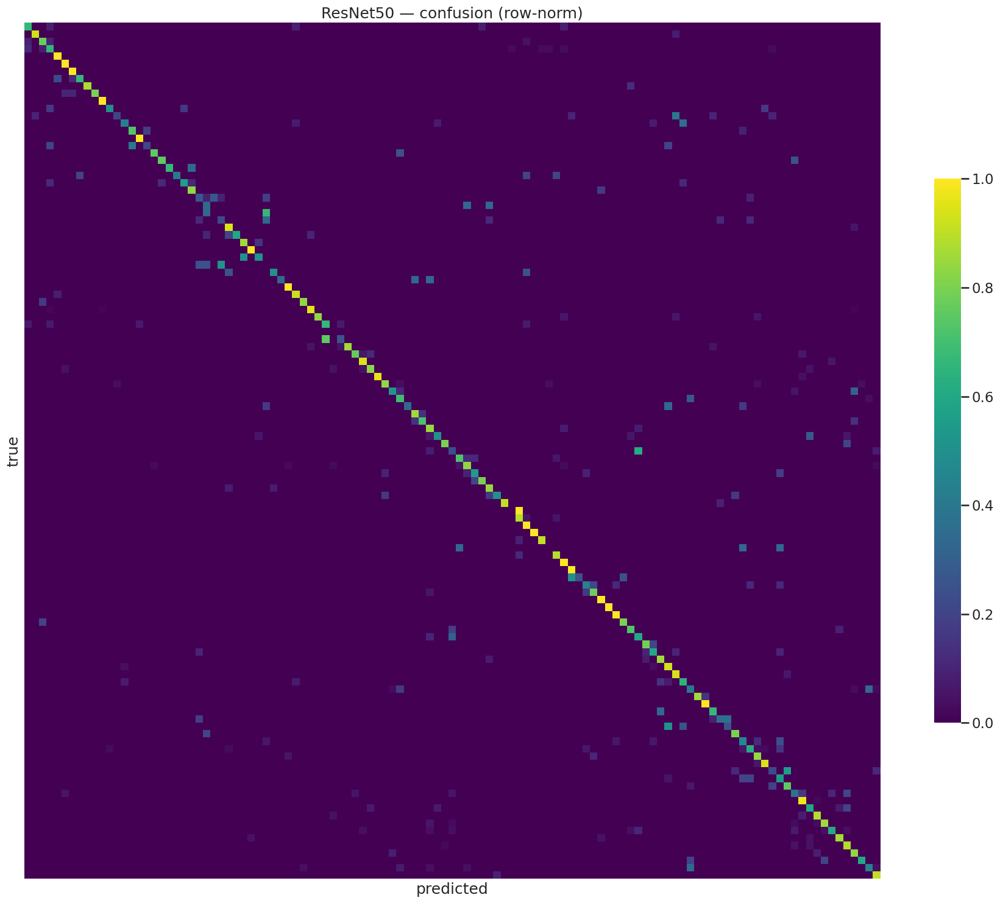

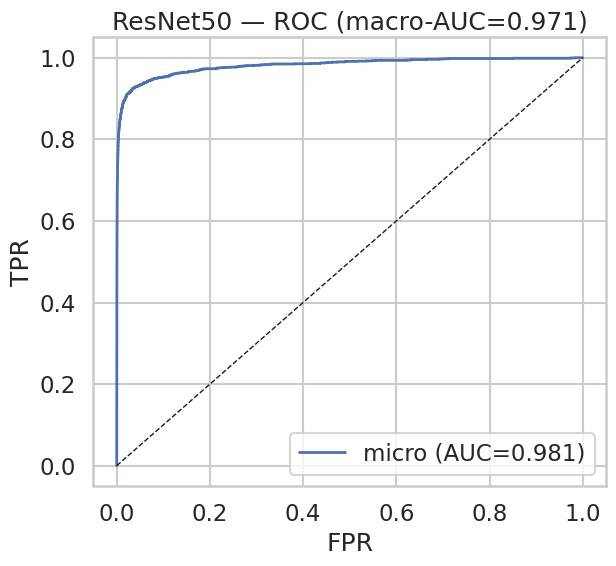

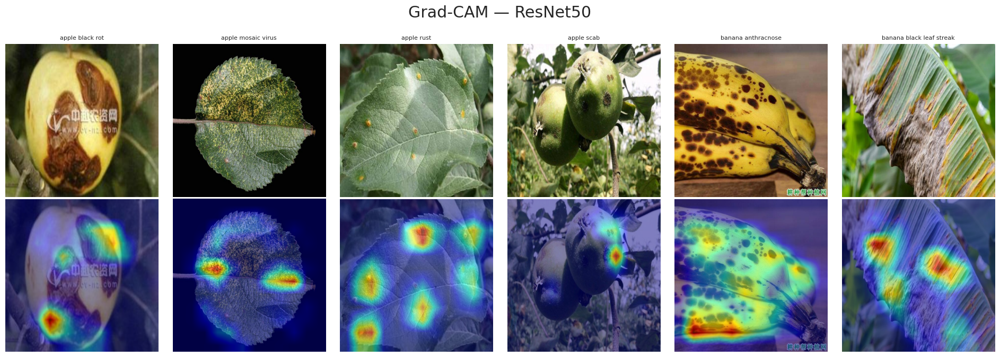


  Training: EfficientNetV2S



model.safetensors:   0%|          | 0.00/86.5M [00:00<?, ?B/s]

[EfficientNetV2S] ep1/40 lr=1.6e-04 trL=5.211 vL=4.730 trA=0.028 vA=0.104
[EfficientNetV2S] ep2/40 lr=3.0e-04 trL=3.349 vL=2.591 trA=0.338 vA=0.611
[EfficientNetV2S] ep3/40 lr=3.0e-04 trL=2.415 vL=2.462 trA=0.543 vA=0.609
[EfficientNetV2S] ep4/40 lr=3.0e-04 trL=1.933 vL=2.288 trA=0.657 vA=0.676
[EfficientNetV2S] ep5/40 lr=3.0e-04 trL=1.657 vL=2.331 trA=0.743 vA=0.649
[EfficientNetV2S] ep6/40 lr=2.9e-04 trL=1.537 vL=2.332 trA=0.780 vA=0.670
[EfficientNetV2S] ep7/40 lr=2.9e-04 trL=1.426 vL=2.234 trA=0.808 vA=0.683
[EfficientNetV2S] ep8/40 lr=2.8e-04 trL=1.388 vL=2.312 trA=0.833 vA=0.671
[EfficientNetV2S] ep9/40 lr=2.8e-04 trL=1.328 vL=2.221 trA=0.851 vA=0.697
[EfficientNetV2S] ep10/40 lr=2.7e-04 trL=1.289 vL=2.324 trA=0.870 vA=0.665
[EfficientNetV2S] ep11/40 lr=2.6e-04 trL=1.257 vL=2.223 trA=0.876 vA=0.697
[EfficientNetV2S] ep12/40 lr=2.5e-04 trL=1.222 vL=2.255 trA=0.890 vA=0.696
[EfficientNetV2S] ep13/40 lr=2.4e-04 trL=1.219 vL=2.255 trA=0.893 vA=0.714
[EfficientNetV2S] ep14/40 lr=2.3e-

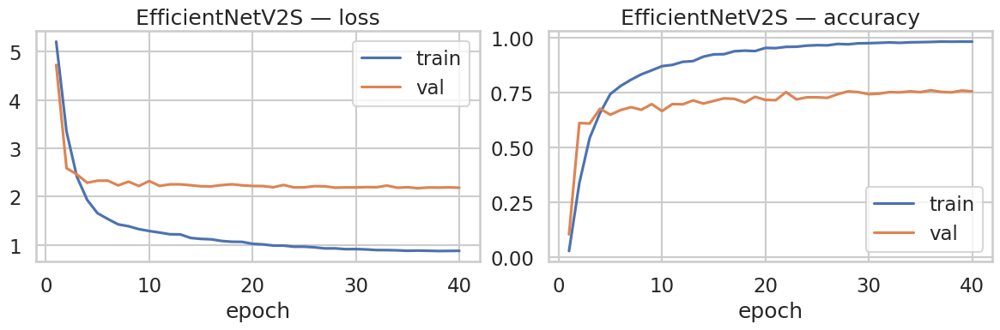

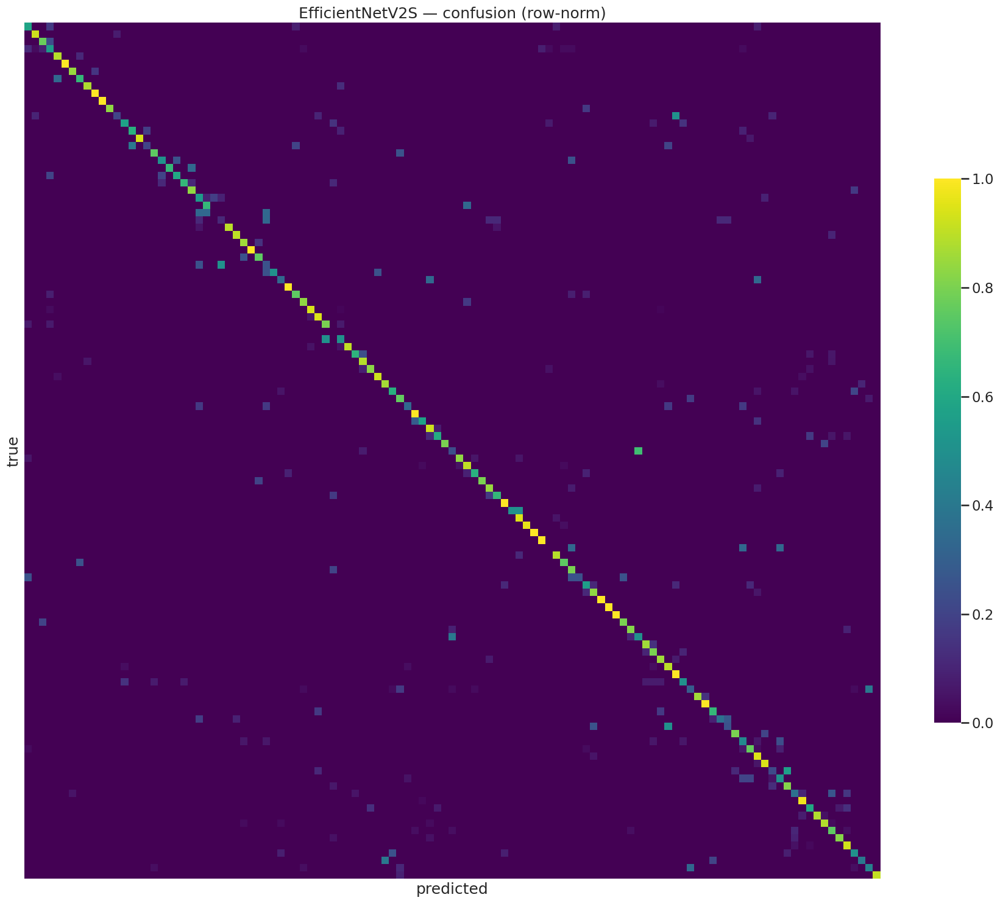

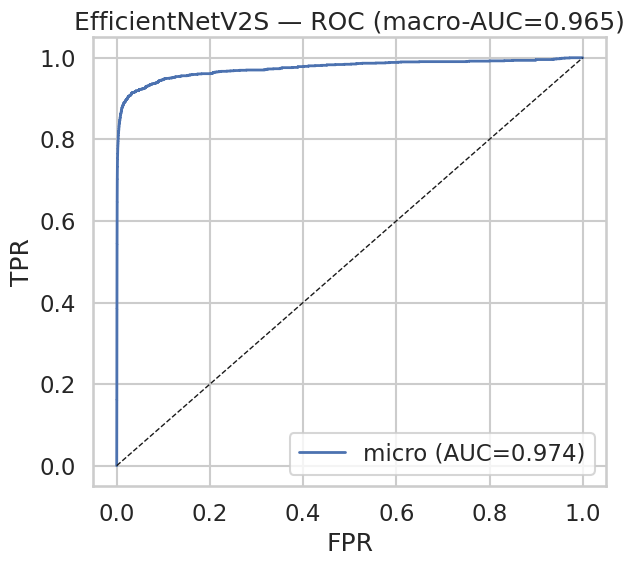

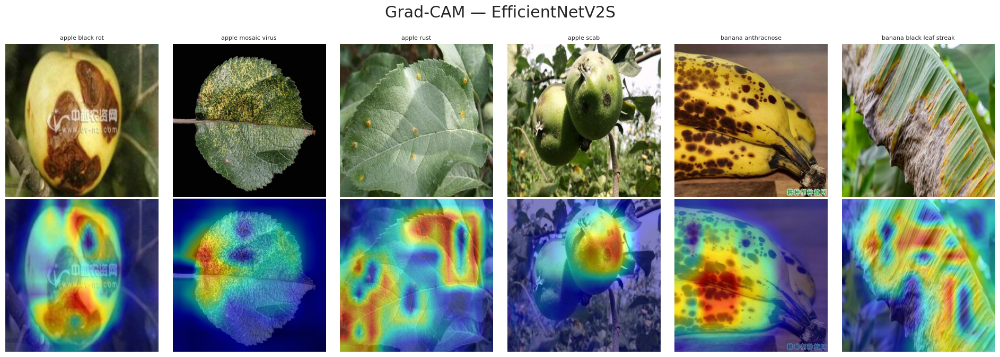


All models trained and saved.


In [9]:
# ============ MAIN LOOP — TRAIN ALL 8 MODELS ============
for MODEL_NAME in MODELS_TO_TRAIN[:4]:  # Session 1 — models 1–4
    print(f"\n{'='*60}")
    print(f"  Training: {MODEL_NAME}")
    print(f"{'='*60}\n")

    t0 = time.time()
    model, img_size, hist, Y, P, PR = train_one(MODEL_NAME)
    train_time = time.time()-t0

    metrics, cm = compute_metrics(Y, P, PR, NUM_CLASSES)
    dep = deployment(model, img_size)

    result = {
        "model_name": MODEL_NAME, "history": hist,
        "y_true": Y, "y_pred": P, "y_prob": PR,
        "metrics": metrics, "cm": cm, "deployment": dep,
        "img_size": img_size, "train_time_sec": train_time,
        "class_names": CLASS_NAMES,
    }
    pickle.dump(result, open(OUTDIR/f"result_{MODEL_NAME}.pkl","wb"))
    print("SAVED", OUTDIR/f"result_{MODEL_NAME}.pkl")
    print({k: round(v,4) for k,v in metrics.items() if isinstance(v, float)})
    print("deployment:", {k: round(v,2) for k,v in dep.items()})

    # Per-model plots
    plot_model_figures(MODEL_NAME, hist, Y, P, PR, img_size)

    # Grad-CAM
    plot_gradcam(MODEL_NAME, model, img_size)

print("\nAll models trained and saved.")
